# **Student Dropout Prediction**
## Created by **Ramses Alexander Coraspe Valdez**
## Created on August 5, 2020

# Installing libraries

In [32]:
# install.packages("genalg")
# install.packages("tidyverse")
# install.packages("cluster")
# install.packages("factoextra")
# install.packages("corrplot")
# install.packages("party")
# install.packages("neuralnet")

# **Importing libraries**

In [33]:
library(genalg)
library(ggplot2)
library(tidyverse)
library(cluster)    
library(factoextra) 
library(neuralnet)

# **Building the dataset**

In [34]:
get_data_assistance <- function(data_r, r1, r2) {
    
  assistance <- vector()
  for(i in 1:1000){
    assistance <- c(assistance, round((sum(asistencias.totales[[i]][,r1:r2]==0) *100) / 192))
  }
  assistance
}

get_data_Biblio <- function(data_r, r1, r2) {  
  suma <- 0
  for(i in 1:1000){
    suma <- suma + sum(data_r[[i]][,r1:r2])
  }  
  factor_biblio <- (round(suma)/1000)/6  
  uso_biblio <- vector()
  for(i in 1:1000){
    uso_biblio <- c(uso_biblio,sum(data_r[[i]][,r1:r2]>=factor_biblio))
  }  
  uso_biblio
}
get_data_plataforma <- function(data_r, r1, r2) {  

  suma <- 0
  for(i in 1:1000){
    suma <- suma + sum(data_r[[i]][,r1:r2])
  }  
  factor_plataforma <- (round(suma)/1000)/6  
  uso_plat <- vector()
  for(i in 1:1000){
    uso_plat <- c(uso_plat,sum(data_r[[i]][,r1:r2]>=factor_plataforma))
  }  
  uso_plat
}
get_data_libros <- function(data_r, r1, r2) {  

  suma <- 0
  for(i in 1:1000){
    suma <- suma + sum(data_r[[i]][,r1:r2])
  }  
  factor_apartado <- (round(suma)/1000)/6  
  apa_Lib <- vector()
  for(i in 1:1000){
    apa_Lib <- c(apa_Lib,sum(data_r[[i]][,r1:r2]>=factor_apartado))
  }  
  apa_Lib
}
get_data_pagos <- function(data_r) {  
  promedio.pagos.mtx <-matrix(,nrow=0,ncol=1)  
  for (i in 1:1000) {
    pagos.vct <- vector()
    pagos.vct[1] <- mean(data_r[[i]][,1:2]) 
    promedio.pagos.mtx <- rbind(promedio.pagos.mtx,pagos.vct)
  }  
  rownames(promedio.pagos.mtx) <- 1:1000  
  #Si hay mas de un retraso enciendo la alarma con 0
  promedio.pagos.mtx[promedio.pagos.mtx < 1.875] <- 0  
  #Minimo un retraso y no se considera con status de pago en alarma
  promedio.pagos.mtx[promedio.pagos.mtx >= 1.875] <- 1  
  promedio.pagos.mtx  
}

get_data_examenes <- function(data_r, r1, r2){  
  promedio.examenes.mtx <- matrix(,nrow=0,ncol=1)  
  for (i in 1:1000) {
    resultados.vct <- vector()
    resultados.vct[1] <- round(mean(data_r[[i]][,r1:r2]))
    promedio.examenes.mtx <- rbind(promedio.examenes.mtx,resultados.vct)    
  }
  rownames(promedio.examenes.mtx) <- 1:1000  
  promedio.examenes.mtx    
}
get_data_trabajos <- function(data_r, r1, r2){  
  promedio.trabajos.mtx <- matrix(,nrow=0,ncol=1)
  for (i in 1:1000) {
    resultados.vct <- vector()
    resultados.vct[1] <- round(mean(data_r[[i]][,r1:r2]))
    promedio.trabajos.mtx <- rbind(promedio.trabajos.mtx,resultados.vct)    
  }
  rownames(promedio.trabajos.mtx) <- 1:1000
  promedio.trabajos.mtx
}
range01 <- function(x){(x-min(x))/(max(x)-min(x))}

In [35]:
load("AsistenciasTotales.R")
f_as_1 <-  get_data_assistance(asistencias.totales, 1, 6)
f_as_2 <-  get_data_assistance(asistencias.totales, 7, 12)

load("perfilAlumnos.R")
perfil.alumnos$genero <- as.numeric(perfil.alumnos$genero)
perfil.alumnos[perfil.alumnos$genero==2,]$genero <- 0
perfil.alumnos$evalucion.socioeconomica <- as.numeric(perfil.alumnos$evalucion.socioeconomica)
perfil.alumnos$edad.ingreso <- as.numeric(perfil.alumnos$edad.ingreso)
data_set <- cbind(perfil.alumnos, f_as_1, f_as_2)

load("ResultadosExamenes.R")
f_examenes_1 <- get_data_examenes(resultados.examenes.totales, 1,6) 
f_examenes_2 <- get_data_examenes(resultados.examenes.totales, 7,12)
data_set <- cbind(data_set, f_examenes_1, f_examenes_2)

load("ResultadoTrabajos.R")
f_trabajos_1 <- get_data_trabajos(resultados.trabajos.totales, 1, 6)
f_trabajos_2 <- get_data_trabajos(resultados.trabajos.totales, 7, 12)
data_set <- cbind(data_set, f_trabajos_1, f_trabajos_2)

load("UsoBiblioteca.R")
f_bibl_1 <-  get_data_Biblio(uso.biblioteca.totales, 1, 6)
f_bibl_2 <-  get_data_Biblio(uso.biblioteca.totales, 7, 12)
data_set <- cbind(data_set, f_bibl_1, f_bibl_2)


load("UsoPlataforma.R")
f_plat_1 <- get_data_plataforma(uso.plataforma.totales, 1, 6)
f_plat_2 <- get_data_plataforma(uso.plataforma.totales, 7, 12)
data_set <- cbind(data_set, f_plat_1, f_plat_2)

load("ApartadoDeLibros.R")
f_libros_1 <- get_data_libros(separacion.libros.totales, 1, 6)
f_libros_2 <- get_data_libros(separacion.libros.totales, 7, 12)
data_set <- cbind(data_set, f_libros_1, f_libros_2)

load("Becas.R")
data_set <- cbind(data_set, distribucion.becas)

load("HistorialPagos.R")
f_pagos_status <-  get_data_pagos(registro.pagos)
data_set <- cbind(data_set, f_pagos_status)

load("CambioCarrera.R")
datos.integrados.R <- cbind(data_set, cambio.carrera)


In [36]:
write.csv(datos.integrados.R,"datos.integrados.csv", row.names = TRUE)
datos.integrados <- read.csv("datos.integrados.csv")
rownames(datos.integrados) <- 1:1000
datos.integrados$X <- NULL

In [37]:
set.seed(3)
ind <- sample(x=c(0,1),size=nrow(datos.integrados),replace=TRUE,prob = c(0.9,0.1))
Training.set <- datos.integrados[ind==0,]
Test.set <- datos.integrados[ind==1,]
Test.set.aux <- Test.set

In [38]:
head(Training.set,20)

,genero,admision.letras,admision.numeros,promedio.preparatoria,edad.ingreso,evalucion.socioeconomica,nota.conducta,f_as_1,f_as_2,f_examenes_1,⋯,f_trabajos_2,f_bibl_1,f_bibl_2,f_plat_1,f_plat_2,f_libros_1,f_libros_2,distribucion.becas,f_pagos_status,cambio.carrera
,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,0,60.09373,35.18746,70.28119,18,4,16,7,8,14,⋯,11,2,0,2,0,2,0,0,1,0
2,0,59.07874,33.15747,67.23621,17,4,15,10,9,14,⋯,13,2,1,2,1,2,1,0,0,0
3,0,53.14335,21.28669,60.00000,15,4,13,12,8,13,⋯,12,1,0,1,0,1,0,0,0,0
4,1,57.00416,29.00832,61.01248,16,4,14,3,5,15,⋯,14,4,3,4,3,4,3,0,1,0
5,0,61.47273,37.94545,74.41818,18,4,16,10,9,13,⋯,12,1,1,1,1,1,1,0,1,0
6,0,61.94897,38.89794,75.84691,18,4,16,11,3,14,⋯,13,3,2,3,2,3,2,0,0,0
7,0,53.95962,22.91924,60.00000,15,4,13,1,3,15,⋯,16,5,6,5,6,5,6,0,0,0
8,0,58.18162,31.36324,64.54486,17,4,15,2,11,15,⋯,13,4,2,4,2,4,2,0,1,0
9,1,51.86664,18.73327,60.00000,14,4,12,1,7,12,⋯,13,0,1,0,1,0,1,0,1,0


In [39]:
head(Test.set,100)

,genero,admision.letras,admision.numeros,promedio.preparatoria,edad.ingreso,evalucion.socioeconomica,nota.conducta,f_as_1,f_as_2,f_examenes_1,⋯,f_trabajos_2,f_bibl_1,f_bibl_2,f_plat_1,f_plat_2,f_libros_1,f_libros_2,distribucion.becas,f_pagos_status,cambio.carrera
,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
28,0,55.63921,26.27841,60.00000,16,4,14,11,22,12,⋯,12,0,0,0,0,0,0,0,1,0
54,0,70.68884,56.37767,100.00000,22,4,20,1,3,15,⋯,16,5,5,5,5,5,5,0,0,0
56,0,63.93171,42.86342,81.79514,19,4,17,6,6,14,⋯,12,2,1,2,1,2,1,0,0,0
73,1,54.75777,24.51554,60.00000,15,4,13,1,6,14,⋯,15,3,4,3,4,3,4,0,1,0
74,0,58.90748,32.81496,66.72245,17,4,15,6,8,15,⋯,12,4,2,4,2,4,2,0,1,0
85,0,62.20121,39.40242,76.60363,18,4,16,4,12,15,⋯,11,4,0,4,0,4,0,0,1,0
90,0,59.63022,34.26044,68.89066,17,4,15,6,5,12,⋯,14,2,3,2,3,2,3,0,1,0
115,1,64.62147,44.24293,83.86440,19,3,17,1,3,14,⋯,14,3,4,3,4,3,4,0,1,0
161,1,63.26583,41.53166,79.79749,19,3,17,8,5,12,⋯,13,1,2,1,2,1,2,0,1,0


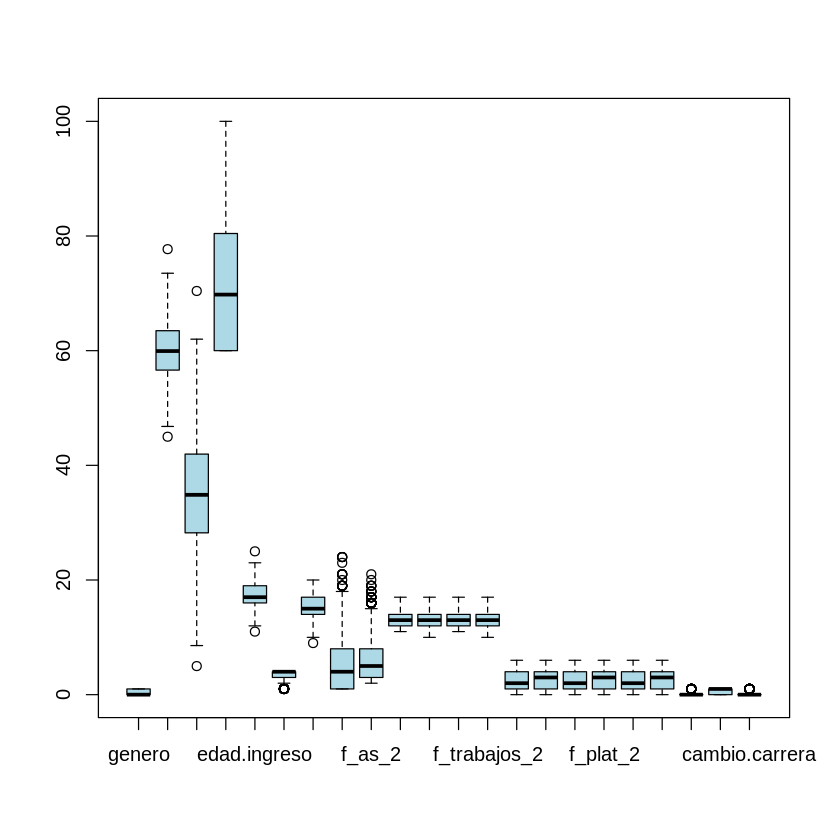

In [40]:
boxplot(Training.set, col = "lightblue")
# Training.set <- apply(Training.set , MARGIN = 2, FUN = function(X) (X - min(X))/diff(range(X)))
# Training.set <- as.data.frame(scale(Training.set))
# boxplot(Training.set,col = "lightblue")

# **Checking for correlations between variables**


row,column,cor,p
<fct>,<fct>,<dbl>,<dbl>
genero,distribucion.becas,0.55000,1.0e-72
genero,cambio.carrera,0.41000,1.2e-38
distribucion.becas,cambio.carrera,0.75000,1.8e-164
genero,f_pagos_status,-0.01500,6.6e-01
distribucion.becas,f_pagos_status,-0.03400,3.0e-01
cambio.carrera,f_pagos_status,-0.00720,8.3e-01
genero,f_as_1,0.06700,4.6e-02
distribucion.becas,f_as_1,0.04900,1.4e-01
cambio.carrera,f_as_1,0.03300,3.2e-01


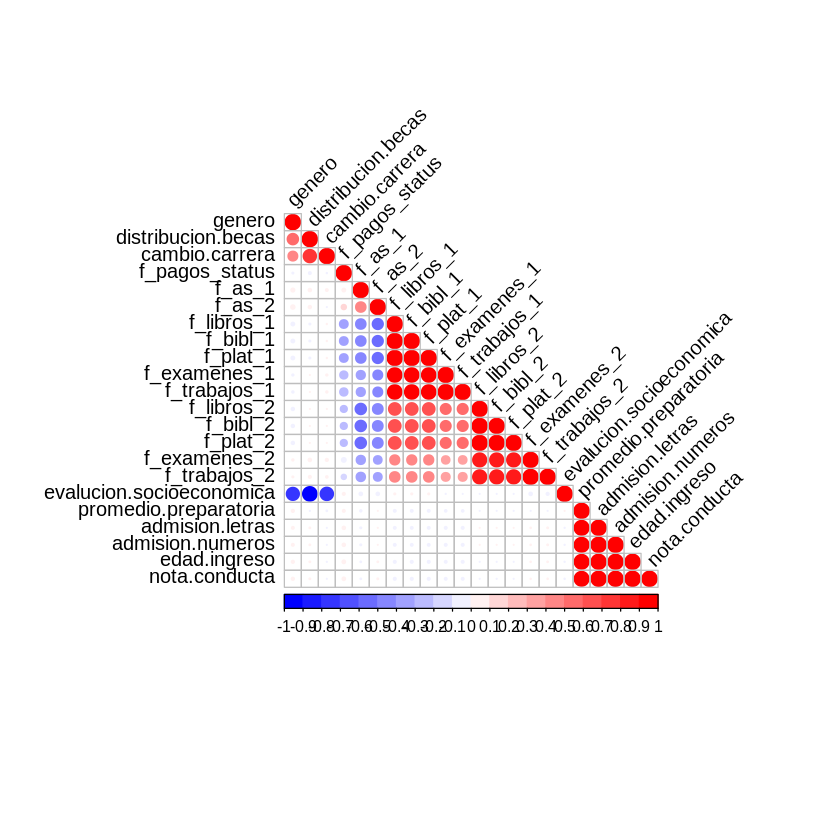

In [41]:
source("http://www.sthda.com/upload/rquery_cormat.r")

col<- colorRampPalette(c("blue", "white", "red"))(20)
rquery.cormat(Training.set, type="flatten", col=col)

# **Removing highly correlated features**

In [42]:
Training.set$nota.conducta <- NULL
Training.set$f_plat_1 <- NULL
Training.set$f_plat_2 <- NULL
Training.set$f_libros_1 <- NULL
Training.set$f_libros_2 <- NULL
Training.set$f_trabajos_1 <- NULL
Training.set$f_trabajos_2 <- NULL

# **Labeling the students using Clustering Analysis with k-means**

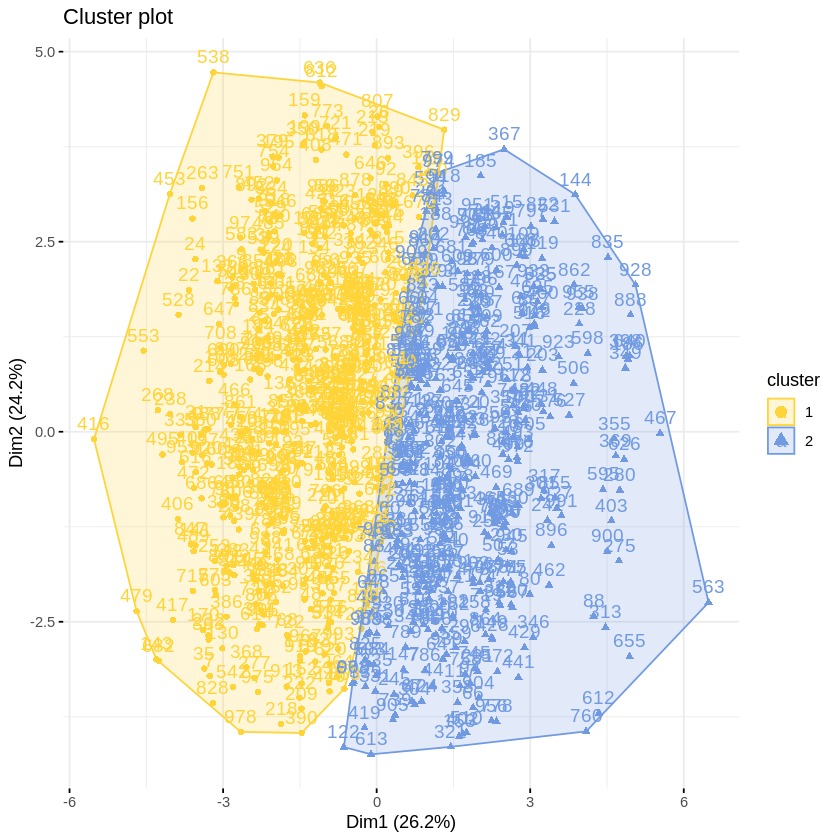

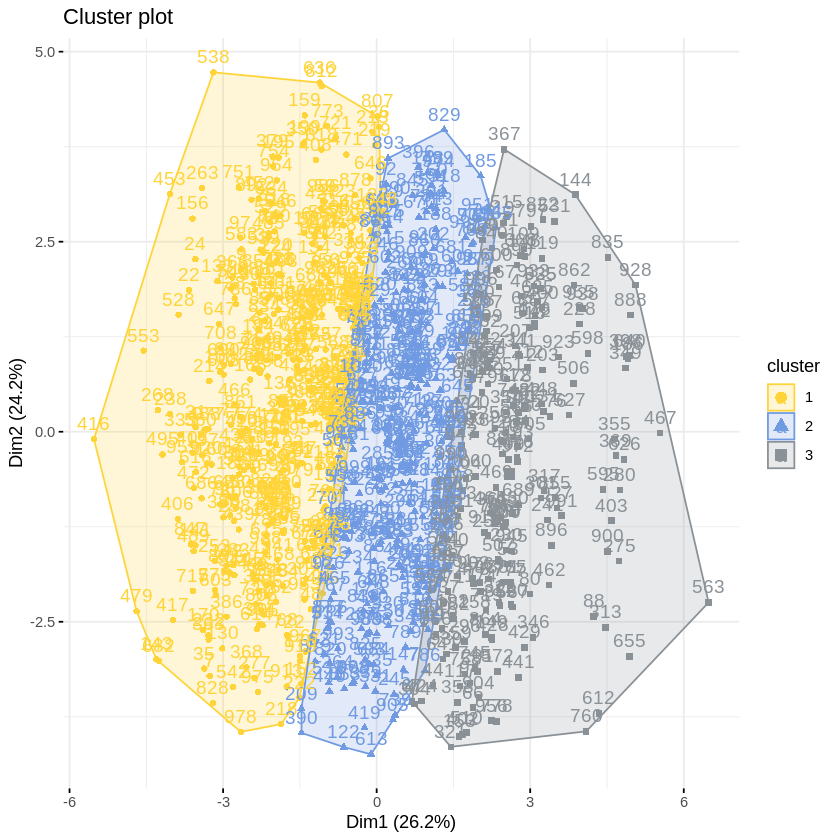

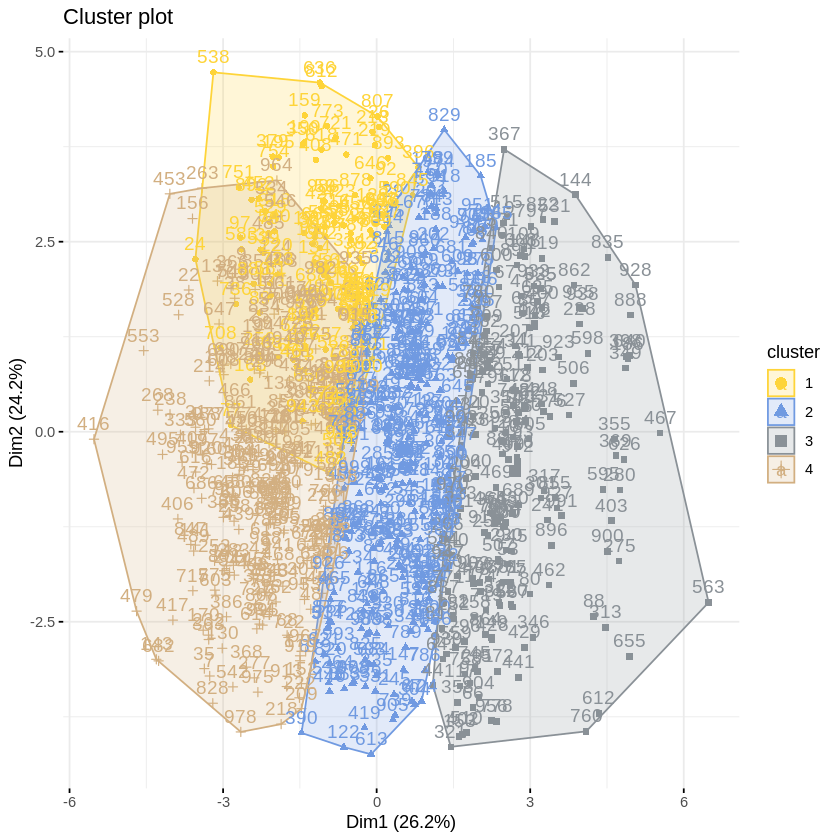

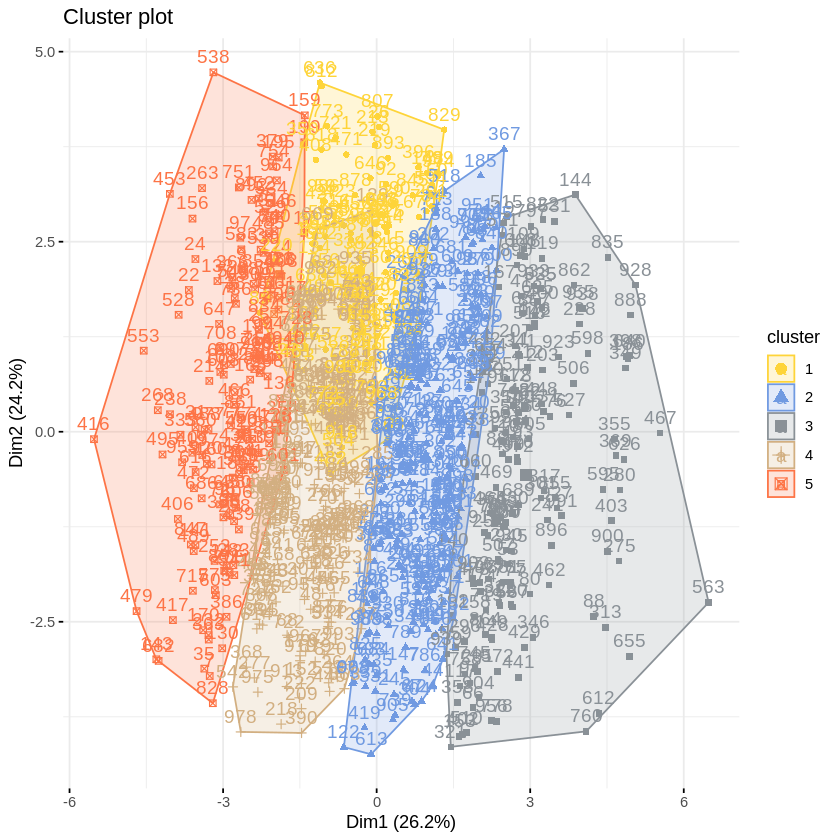

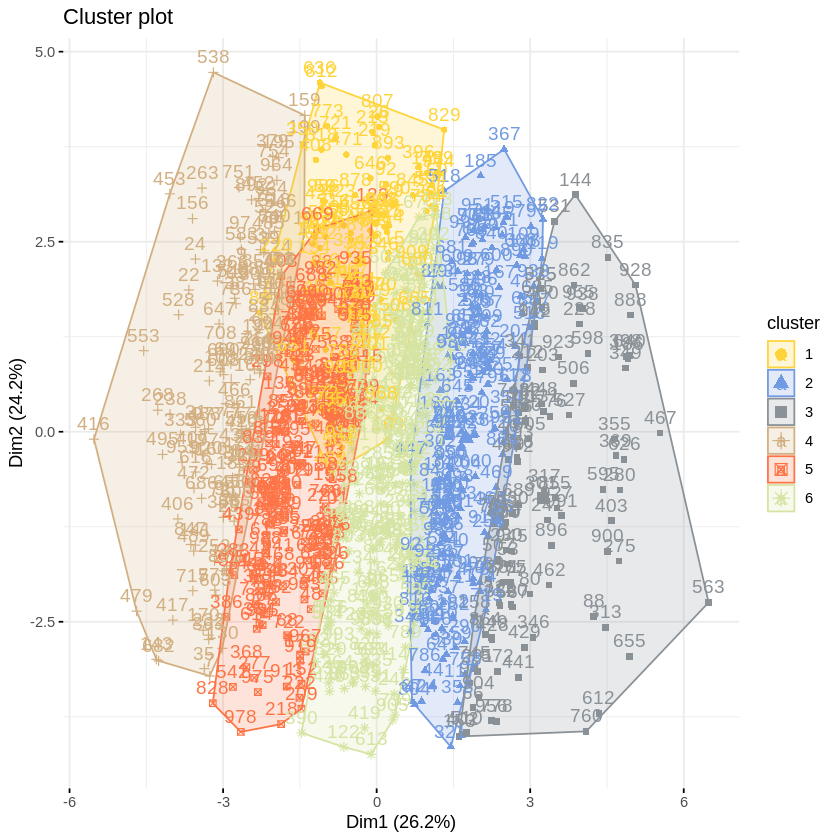

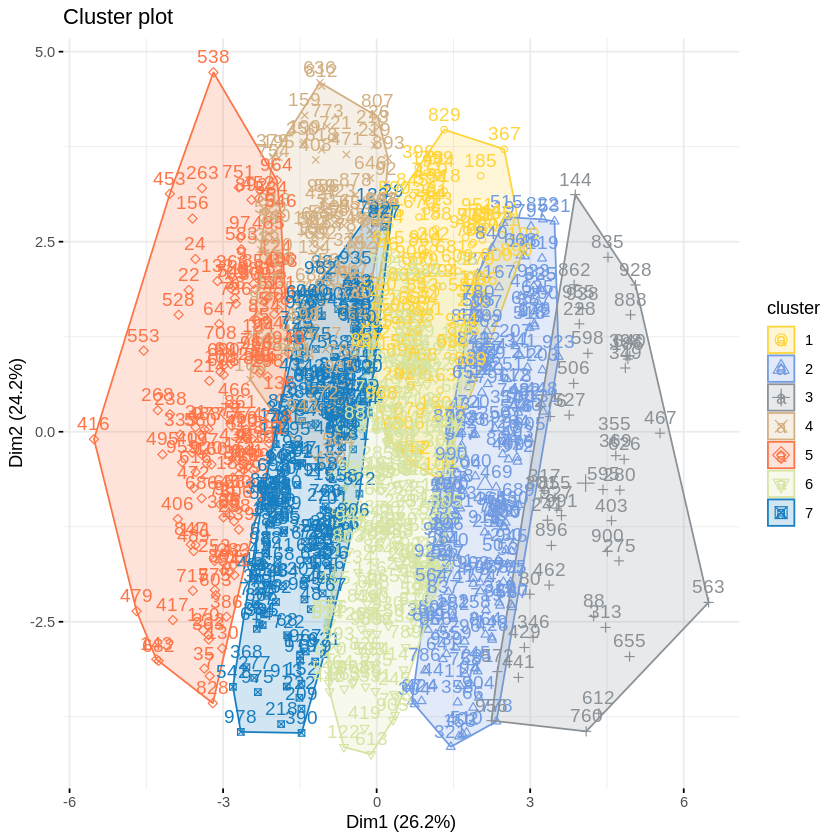

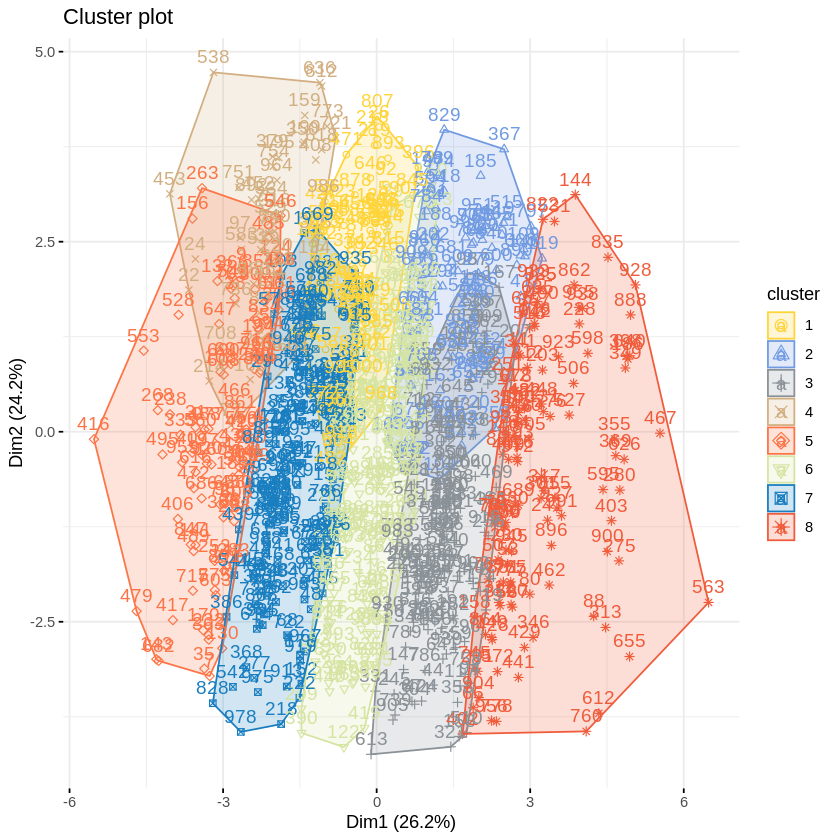

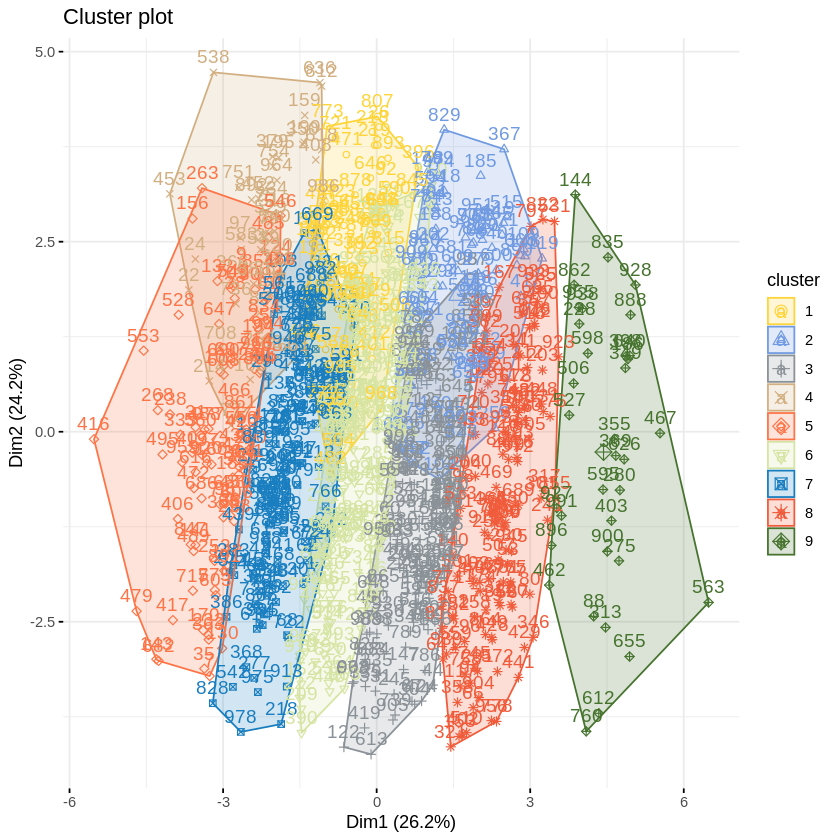

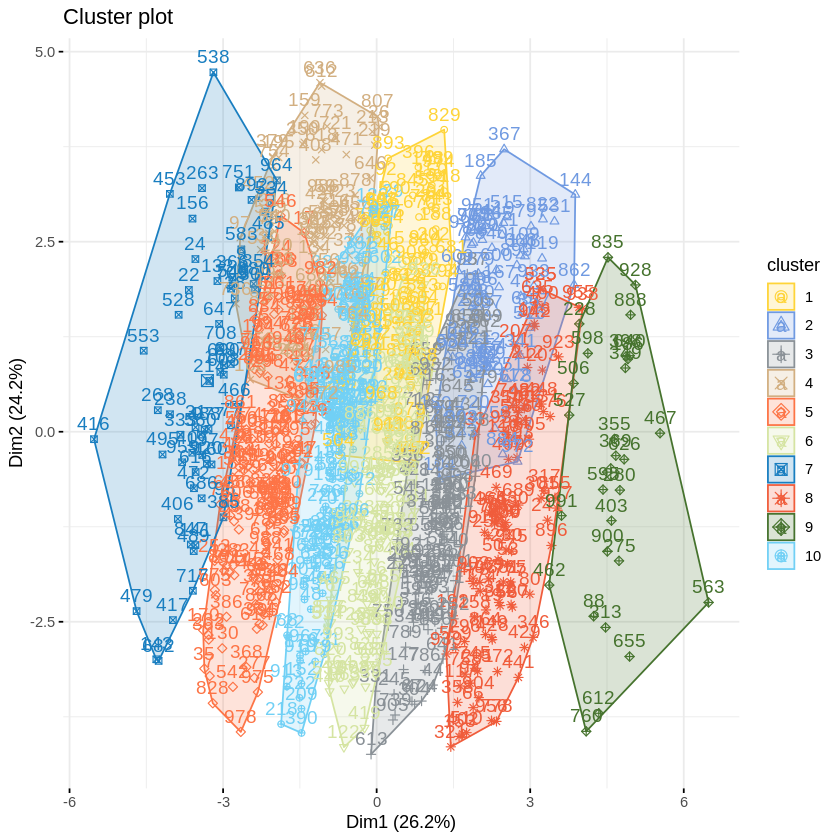

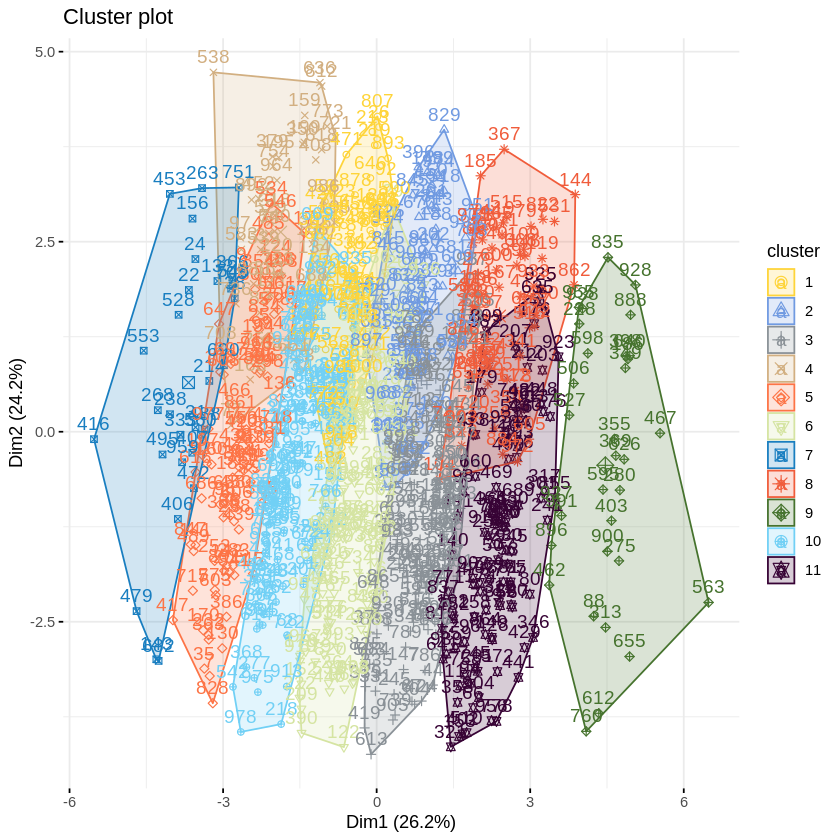

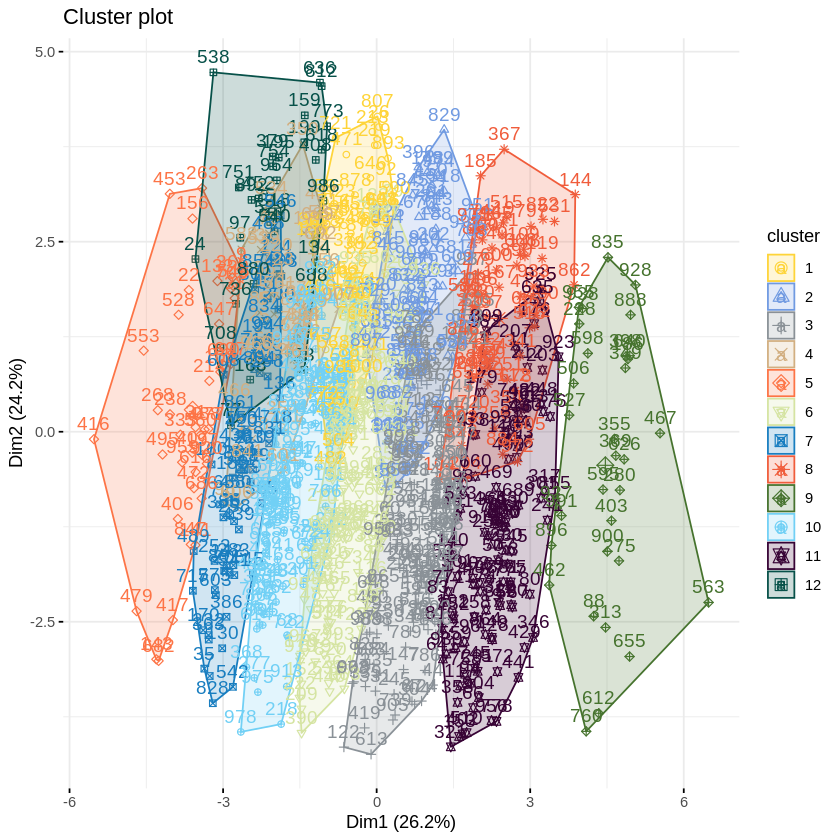

In [43]:
set.seed(123)
pal_color = "simpsons"

kplot2 <- kmeans(Training.set, centers = 2, iter.max = 25, nstart = 1)
plot2 <-  fviz_cluster(kplot2, data = Training.set, ellipse.type = "convex",palette = pal_color,ggtheme = theme_minimal())
plot2

set.seed(123)
kplot3 <- kmeans(Training.set, centers = 3, iter.max = 25, nstart = 1)
plot3 <-  fviz_cluster(kplot3, data = Training.set,ellipse.type = "convex",palette = pal_color,ggtheme = theme_minimal())
plot3

set.seed(123)
kplot4 <- kmeans(Training.set, centers = 4, iter.max = 25, nstart = 1)
plot4 <-  fviz_cluster(kplot4, data = Training.set, ellipse.type = "convex",palette = pal_color,ggtheme = theme_minimal())
plot4

set.seed(123)
kplot5 <- kmeans(Training.set, centers = 5, iter.max = 25, nstart = 1)
plot5 <-  fviz_cluster(kplot5, data = Training.set,ellipse.type = "convex", palette = pal_color,ggtheme = theme_minimal())
plot5

set.seed(123)
kplot6 <- kmeans(Training.set, centers = 6, iter.max = 25, nstart = 1)
plot6 <-  fviz_cluster(kplot6, data = Training.set,ellipse.type = "convex",palette = pal_color,ggtheme = theme_minimal())
plot6

set.seed(123)
kplot7 <- kmeans(Training.set, centers = 7, iter.max = 25, nstart = 1)
plot7 <-  fviz_cluster(kplot7, data = Training.set,ellipse.type = "convex",palette = pal_color, ggtheme = theme_minimal())
plot7

set.seed(123)
kplot8 <- kmeans(Training.set, centers = 8, iter.max = 25, nstart = 1)
plot8 <-  fviz_cluster(kplot8, data = Training.set,ellipse.type = "convex",palette = pal_color,ggtheme = theme_minimal())
plot8

set.seed(123)
kplot9 <- kmeans(Training.set, centers = 9, iter.max = 25, nstart = 1)
plot9 <-  fviz_cluster(kplot9, data = Training.set,ellipse.type = "convex",palette = pal_color,ggtheme = theme_minimal())
plot9


set.seed(123)
kplot10 <- kmeans(Training.set, centers = 10, iter.max = 25, nstart = 1)
plot10 <-  fviz_cluster(kplot10, data = Training.set,ellipse.type = "convex", palette = pal_color,ggtheme = theme_minimal())
plot10

set.seed(123)
kplot11 <- kmeans(Training.set, centers = 11, iter.max = 25, nstart = 1)
plot11 <-  fviz_cluster(kplot11, data = Training.set,ellipse.type = "convex", palette = pal_color,ggtheme = theme_minimal())
plot11

set.seed(123)
kplot12 <- kmeans(Training.set, centers = 12, iter.max = 25, nstart = 1)
plot12 <-  fviz_cluster(kplot12, data = Training.set,ellipse.type = "convex",palette = pal_color,ggtheme = theme_minimal())
plot12


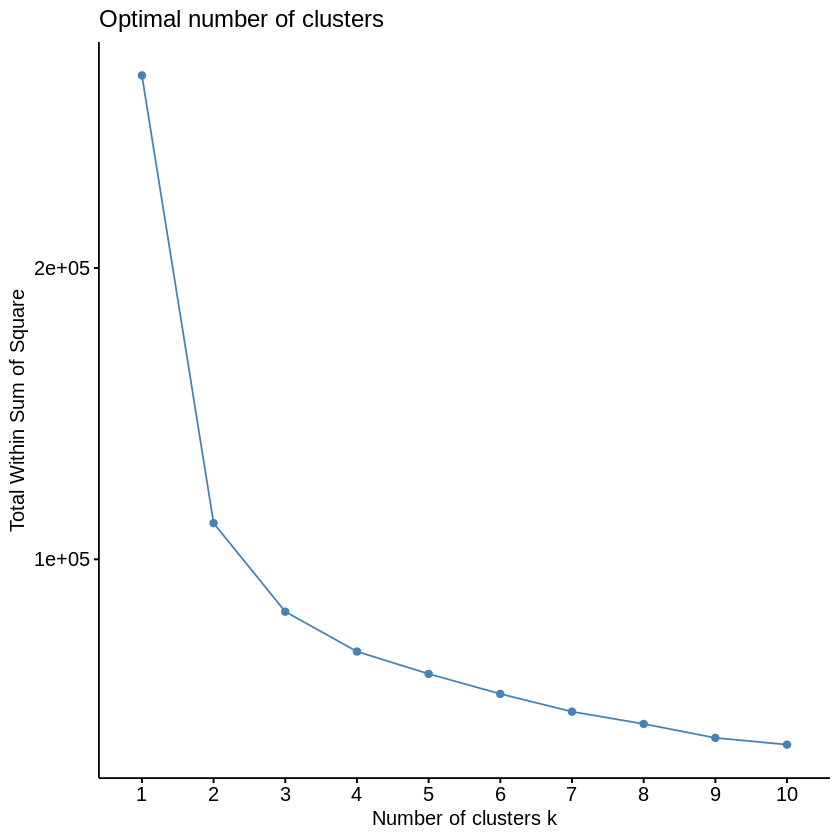

In [44]:
set.seed(123)
fviz_nbclust(Training.set, kmeans, method = "wss")

In [45]:
kplot12$size
kplot12$centers

[1]  61  79 142  43  40 123  65  68  32 115 102  30

,genero,admision.letras,admision.numeros,promedio.preparatoria,edad.ingreso,evalucion.socioeconomica,f_as_1,f_as_2,f_examenes_1,f_examenes_2,f_bibl_1,f_bibl_2,distribucion.becas,f_pagos_status,cambio.carrera
1,0.4590164,58.06022,31.12044,64.22752,16.75410,3.295082,12.491803,9.786885,12.78689,12.73770,1.196721,1.327869,0.24590164,0.8360656,0.14754098
2,0.4430380,61.11272,37.22544,73.33815,17.98734,3.329114,10.531646,10.101266,12.82278,12.74684,1.189873,1.392405,0.22784810,0.7848101,0.08860759
3,0.3239437,62.64771,40.29541,77.94312,18.56338,3.619718,2.852113,4.253521,13.91549,13.58451,2.978873,3.500000,0.10563380,0.6971831,0.05633803
4,0.4186047,54.95433,24.90866,60.09164,15.46512,3.581395,10.372093,5.534884,13.16279,12.81395,1.627907,1.604651,0.11627907,0.7674419,0.09302326
5,0.4500000,50.20282,15.40564,60.00000,13.57500,3.550000,3.750000,5.225000,13.70000,13.35000,2.625000,3.075000,0.10000000,0.6750000,0.07500000
6,0.4146341,59.46333,33.92666,68.38999,17.26016,3.365854,3.349593,4.406504,13.75610,13.62602,2.772358,3.235772,0.21138211,0.7154472,0.13821138
7,0.2769231,53.79678,22.59356,60.00000,15.03077,3.646154,2.723077,4.169231,14.03077,13.47692,3.107692,3.230769,0.07692308,0.6461538,0.04615385
8,0.4705882,64.80062,44.60125,84.40187,19.41176,3.514706,11.014706,10.676471,12.77941,12.55882,1.014706,1.102941,0.11764706,0.7058824,0.08823529
9,0.4375000,70.53223,56.06445,98.40075,21.81250,3.500000,6.718750,6.406250,13.18750,13.00000,1.875000,2.218750,0.12500000,0.8125000,0.06250000
10,0.3739130,56.91408,28.82817,61.46394,16.31304,3.391304,2.600000,4.834783,13.86087,13.71304,2.956522,3.408696,0.21739130,0.7043478,0.13043478


### Insights about the K choosed (K=12)

**The students will be separated in two groups:**

> Students at risk of dropping out

> Students who do not drop out

Lets clarify some features of this analysis:

1.   The variable "**f_as_1**" is the percentage of absence of the student in semester 1 and the variable "**f_as_2**"  is the percentage of absence of the student in semester 2, if the value is very high then the student has been absent many times in that semester and this is an indicator of possible dropout, the clusters 1, 2, 8 and 12 are the hihger values for these variables

2. The variable "**f_examenes_1**" is the average of the student's exam scores in semester 1 and the variable "**f_examenes_2** is the average of the student's exams scores for semester 2, in the previous table it can be seen that both are the lower for clusters 1, 2, 8 and 12, these are very clear indicators of a possible risk of dropout.

3. The variables "**f_bibl_1**" is the factor of university use of the library in semester 1 and the variable "**f_bibl_2**" is the factor of university use of the library for semester 2 of the student, both variables mean how frequent the use is of the university's educational resources for a student and their interest in studying and researching. A very low value represents a possible dropout case, the clusters 1, 2, 8 and 12 are the lower values for these variables.



In [46]:
Training.set <- cbind(Training.set, cluster = kplot12$cluster) 
Training.set <- cbind(Training.set, dropout = kplot12$cluster)

Training.set[Training.set$cluster==1,]$dropout  <- 1
Training.set[Training.set$cluster==2,]$dropout  <- 1
Training.set[Training.set$cluster==8,]$dropout  <- 1
Training.set[Training.set$cluster==12,]$dropout <- 1

Training.set[Training.set$cluster==3,]$dropout  <- 0
Training.set[Training.set$cluster==4,]$dropout  <- 0
Training.set[Training.set$cluster==5,]$dropout  <- 0
Training.set[Training.set$cluster==6,]$dropout  <- 0
Training.set[Training.set$cluster==7,]$dropout  <- 0
Training.set[Training.set$cluster==9,]$dropout  <- 0
Training.set[Training.set$cluster==10,]$dropout <- 0
Training.set[Training.set$cluster==11,]$dropout <- 0

Training.set$cluster <- NULL

In [47]:
sum(Training.set$dropout==1)
sum(Training.set$dropout==0)

[1] 238

[1] 662

# **Data Normalization**

In [48]:
test_rows <- rownames(Test.set)

Training.set <- as.data.frame(scale(Training.set))
Test.set <- as.data.frame(scale(Test.set))

normalize <- function(x) {
  return ((x - min(x)) / (max(x) - min(x)))
}

Training.set <- as.data.frame(lapply(Training.set, normalize))
Test.set <- as.data.frame(lapply(Test.set, normalize)) 

rownames(Test.set) <- test_rows


# **Splitting the 900 students in two groups, Training (700) and Evaluation (200)**

In [49]:
set.seed(12345)

rows <- sample(nrow(Training.set))
Complete.set <- Training.set[rows, ]

Training.set   <- tail(Complete.set, 700)
Evaluation.set <- head(Complete.set, 200)

nrow(Training.set)
nrow(Evaluation.set)

[1] 700

[1] 200

# **Creating a model using ANN to predict possible dropout students**

### Training the model with the 700 students of the Training set

In [50]:
nn=neuralnet(dropout~genero+admision.letras+admision.numeros+promedio.preparatoria+edad.ingreso+evalucion.socioeconomica+f_as_1+f_as_2+f_examenes_1+f_examenes_2+f_bibl_1+f_bibl_2+distribucion.becas+f_pagos_status+cambio.carrera, 
             data=Training.set, 
             hidden=c(10,5,3), 
             act.fct = "logistic", 
             linear.output = FALSE,
             stepmax=10^5,threshold = 0.01)


In [51]:
plot(nn)

### Testing the model with the 200 students of the Evaluation set

In [52]:
temp_test <- subset(Evaluation.set, select = c("genero","admision.letras","admision.numeros","promedio.preparatoria","edad.ingreso","evalucion.socioeconomica","f_as_1","f_as_2","f_examenes_1","f_examenes_2","f_bibl_1","f_bibl_2","distribucion.becas","f_pagos_status","cambio.carrera"))
nn.results <- compute(nn, temp_test)
results <- data.frame(actual = Evaluation.set$dropout, prediction = nn.results$net.result)

### 94% of accuracy predicting with the evaluation set

In [53]:
roundedresults<-sapply(results,round,digits=0)
roundedresultsdf=data.frame(roundedresults)
attach(roundedresultsdf)
confusion_table <- table(actual,prediction)
confusion_table
n <- sum(confusion_table)
diag <- diag(confusion_table) 
accuracy <- sum(diag) / n
accuracy

The following objects are masked from roundedresultsdf (pos = 3):

    actual, prediction




      prediction
actual   0   1
     0 145   4
     1   8  43

[1] 0.94

### Testing the  model with the 100 students of the Test set

In [54]:
temp_test <- subset(Test.set, select = c("genero","admision.letras","admision.numeros","promedio.preparatoria","edad.ingreso","evalucion.socioeconomica","f_as_1","f_as_2","f_examenes_1","f_examenes_2","f_bibl_1","f_bibl_2","distribucion.becas","f_pagos_status","cambio.carrera"))
nn.results <- compute(nn, temp_test)
results <- data.frame(row= rownames(Test.set), prediction = round(nn.results$net.result))
students_prediction_rows <- as.vector(results[results$prediction==1,]$row)

# **Showing the most likely students which could dropout**

In [138]:
Test.set.aux <- subset(Test.set.aux, select = c("genero","admision.letras","admision.numeros","promedio.preparatoria","edad.ingreso","evalucion.socioeconomica","f_as_1","f_as_2","f_examenes_1","f_examenes_2","f_bibl_1","f_bibl_2","distribucion.becas","f_pagos_status","cambio.carrera"))
dropout_students <- Test.set.aux[students_prediction_rows,]
dropout_students$id_alumno <- seq(1:length(students_prediction_rows))
dropout_students


,genero,admision.letras,admision.numeros,promedio.preparatoria,edad.ingreso,evalucion.socioeconomica,f_as_1,f_as_2,f_examenes_1,f_examenes_2,f_bibl_1,f_bibl_2,distribucion.becas,f_pagos_status,cambio.carrera,id_alumno
,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
28,0,55.63921,26.27841,60.00000,16,4,11,22,12,12,0,0,0,1,0,1
161,1,63.26583,41.53166,79.79749,19,3,8,5,12,13,1,2,0,1,0,2
288,0,58.71338,32.42675,66.14013,17,4,9,12,12,12,0,0,0,0,0,3
310,1,54.11977,23.23953,60.00000,15,3,22,10,14,11,3,0,0,0,0,4
451,1,65.81984,46.63968,87.45951,20,3,21,14,13,14,1,3,0,1,0,5
484,0,64.19345,43.38690,82.58035,19,4,14,14,13,12,1,0,0,1,0,6
499,1,55.45277,25.90553,60.00000,16,3,9,12,12,13,0,2,0,1,0,7
569,0,61.83595,38.67190,75.50785,18,4,9,6,12,12,0,0,0,1,0,8
698,0,63.26870,41.53740,79.80610,19,4,5,13,14,13,2,2,0,1,0,9


# **Use of Genetic Algorithm for avoid Students Dropout**

In [ ]:
#10000 USD
budget.limit <- 10000 

items <- data.frame(                    

student.features = c('beca.estudiantil', 'vales.transporte',
                     'consulta.psicologica', 'asesor.individual',
                     'curso.remedial', 'visita.empresa',
                     'platica.motivacional', 'viaje.recreativo',
                     'mentoria', 'comedor.gratuito'),

budget.features = c(500, 100, 
                   300, 200, 
                   1000,30,
                   50, 150,
                   200, 250)                   
)

n_students <- length(students_prediction_rows)
n_features <- nrow(items)

get_budget_chromosome <- function(g, b, nf){
    budget <- 0

    for(i in 1:nf){
        if(g[i]==1){  budget <- budget + b[i] }            
    }

    budget 
}

get_punishment<- function(i, g){

    punish.value <- 0

   #Get genetic data from the chunk related to the student
    beca <- g[1]
    asesor.individual <- g[4]
    curso.remedial <- g[5]
    platica.motivacional <-g[7]
    mentoria <- g[9]
    comedor.gratuito <- g[10]

    #Get the actual data from the student
    std <- dropout_students[dropout_students$id_alumno==i,]
    eval.economica <- as.integer(std$evalucion.socioeconomica)
    prom.prepa <- as.double(std$promedio.preparatoria)
    edad <- as.integer(std$edad.ingreso)
    cambio.carrera <- as.integer(std$cambio.carrera)
    f_pagos_status <- as.integer(std$f_pagos_status)
    beca_estudiante <- as.integer(std$distribucion.becas)

    flag = FALSE

    if(beca == 1 && beca_estudiante == 1){
        punish.value <- punish.value + 50
        flag = TRUE    
    }
    if(edad < 22 && platica.motivacional == 0){
        punish.value <- punish.value + 20
        flag = TRUE
    }
    if(cambio.carrera == 1 && platica.motivacional == 0){
        punish.value <- punish.value + 10
        flag = TRUE
    }
    if(f_pagos_status==0 && eval.economica == 4 && beca_estudiante == 0){
        punish.value <- punish.value + 50
        flag = TRUE
    }
    if(prom.prepa > 70  && eval.economica == 4 && beca_estudiante == 0){
        punish.value <- punish.value + 60
        flag = TRUE
    }
    if(prom.prepa <= 70  && eval.economica == 4 && beca_estudiante == 0){
        punish.value <- punish.value + 20
        flag = TRUE
    }
    if(eval.economica == 3 && edad < 22 && asesor.individual == 0){
        punish.value <- punish.value + 20
        flag = TRUE
    }
    else { }
    
    punish.value <- if(flag==FALSE) -1 else punish.value
    
    punish.value

}

fitness.generic <- function(x) {


    current.budget <- 0
    punish.value <- -1

    iter <- 1
    for(i in 1:n_students) {
        
        student_genes <- x[iter:(n_features * i)]
        current.budget <- current.budget + get_budget_chromosome(student_genes,items$budget.features,n_features)    
        punish.value <- punish.value + get_punishment(i, student_genes)
        iter <- iter + n_features

    }

    if(current.budget > budget.limit){
        return(0)
    }
    else{
        return(punish.value)
    }
}



?rbga.bin
ga.one <- rbga.bin(size=(n_students*n_features),
                   iters=200,
                   mutationChance=0.01,
                   elitism = 50,
                   evalFunc = fitness.generic,
                   verbose = T
)

In [134]:
Finalbudget <- 0
best <- ga.one$population[ga.one$evaluations == min(ga.one$best),][1,]

iter <- 1
for(i in 1:n_students) {
    
    best_genes <- best[iter:(n_features * i)]
    print(rownames(dropout_students[dropout_students$id_alumno==i,]))
    print(best_genes)
    best.items <- items$student.features[best_genes == 1]
    print(best.items)
    Finalbudget <- Finalbudget + best_genes %*% items$budget.features
    iter <- iter + n_features
}

Finalbudget

[1] "28"
 [1] 0 0 0 0 0 0 1 0 0 0
[1] platica.motivacional
10 Levels: asesor.individual beca.estudiantil ... visita.empresa
[1] "161"
 [1] 0 0 0 1 0 0 1 0 0 0
[1] asesor.individual    platica.motivacional
10 Levels: asesor.individual beca.estudiantil ... visita.empresa
[1] "288"
 [1] 0 0 0 0 0 0 1 1 0 0
[1] platica.motivacional viaje.recreativo    
10 Levels: asesor.individual beca.estudiantil ... visita.empresa
[1] "310"
 [1] 0 0 0 1 0 1 1 0 0 0
[1] asesor.individual    visita.empresa       platica.motivacional
10 Levels: asesor.individual beca.estudiantil ... visita.empresa
[1] "451"
 [1] 0 0 0 1 0 0 1 0 0 0
[1] asesor.individual    platica.motivacional
10 Levels: asesor.individual beca.estudiantil ... visita.empresa
[1] "484"
 [1] 0 0 0 0 0 0 1 0 0 0
[1] platica.motivacional
10 Levels: asesor.individual beca.estudiantil ... visita.empresa
[1] "499"
 [1] 0 1 0 1 0 0 1 0 0 0
[1] vales.transporte     asesor.individual    platica.motivacional
10 Levels: asesor.individual beca.estudianti

5240


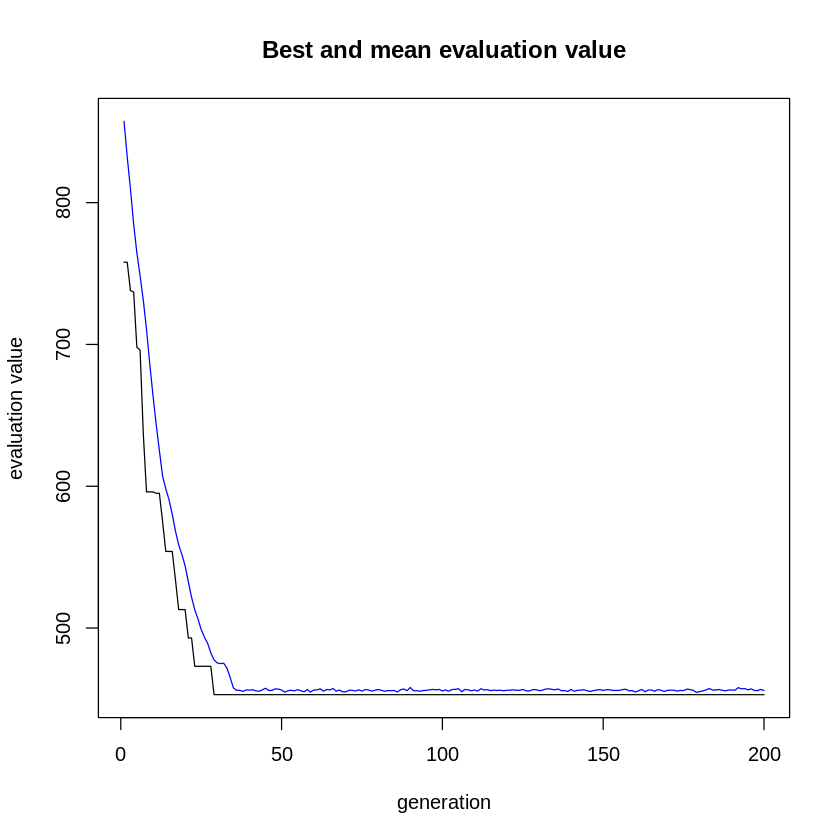

In [131]:
plot(ga.one)